In [48]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from scipy.special import jv
import os
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
import mpmath
from mpmath import *
import time
import pandas as pd



os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)

from DTT_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Initialize parameters

In [49]:
plot=1

In [50]:
os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Calibration')

f = 1500
coeff = 0.65 #diffraction limit coeff

lda = 500e-9
d0 = coeff*lda
delta_y = 300e-9


Lambda = np.linspace(375e-9, 1040e-9, 500)
D0 = coeff*Lambda
Delta_y = np.linspace(1e-12, 700e-9, 500)



## Compare Airy response functions

Make FWHM vary

In [51]:
t_i = time.time()
#Compare all Airy response functions
#Compare all Airy response functions
Res_int = R2F_int(D0, delta_y)
t1 = time.time()
print('Temps pour version intégrale : {}'.format(t1-t_i))


Res_ana_list=[]

for x in D0 :
    Res_ana_list.append(R2F_ana(x, delta_y))
Res_ana_lda = np.array(Res_ana_list)
t2 = time.time()
print('Temps pour version analytique : {}'.format(t2-t1))


Res_DL = R2F_DL(D0, delta_y)
t3 = time.time()
print('Temps pour version DL : {}'.format(t3-t2))

Temps pour version intégrale : 0.3569650650024414
Temps pour version analytique : 0.030530691146850586
Temps pour version DL : 0.0


<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:11: SyntaxWarning: invalid escape sequence '\g'
<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:11: SyntaxWarning: invalid escape sequence '\g'
C:\Users\nberr\AppData\Local\Temp\ipykernel_15848\4279727243.py:9: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$ (nm)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_15848\4279727243.py:11: SyntaxWarning: invalid escape sequence '\g'
  plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')


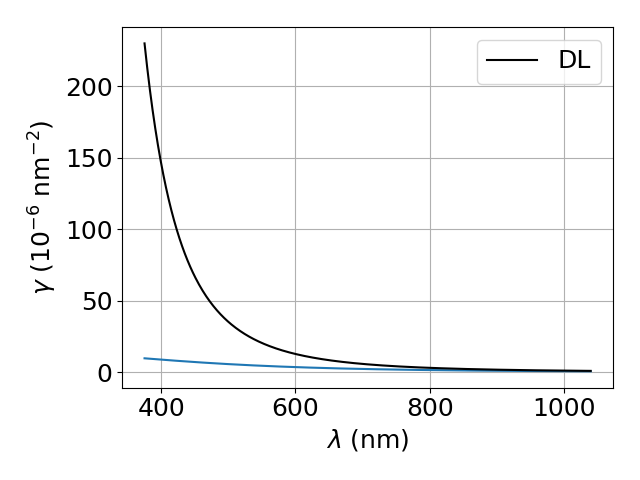

In [52]:
if plot :
        
    fig = plt.figure()

    plt.plot(Lambda*1e9, np.array(Res_ana_lda*1e-12))
    #plt.plot(Lambda*1e9, Res_int*1e-12, linestyle='--', label="methode intégrale")
    plt.plot(Lambda*1e9, -Res_DL*1e-12, color='black', label='DL')

    plt.xlabel('$\lambda$ (nm)')
    
    plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')
    plt.legend()
    plt.grid()
    plt.tight_layout()


    # plt.savefig('Comparaison analytique et integral en fonction de lambda.png')
    # plt.savefig('Comparaison analytique et integral en fonction de lambda.pdf')

    # plt.savefig('Comparaison analytique et DL en fonction de lambda.png')
    # plt.savefig('Comparaison analytique et DL en fonction de lambda.pdf')

Make Delta_y vary

In [53]:
t_i = time.time()
Res_int = R2F_int(d0, Delta_y)
t1 = time.time()
print('Temps pour version intégrale : {}'.format(t1-t_i))


Res_ana_list=[]

for dy in Delta_y :
    Res_ana_list.append(R2F_ana(d0, dy))
Res_ana = np.array(Res_ana_list)
t2 = time.time()
print('Temps pour version analytique : {}'.format(t2-t1))


Res_DL = R2F_DL(d0, Delta_y)
t3 = time.time()
print('Temps pour version DL : {}'.format(t3-t2))



Temps pour version intégrale : 0.39974021911621094
Temps pour version analytique : 0.027842998504638672
Temps pour version DL : 0.0


<>:9: SyntaxWarning: invalid escape sequence '\d'
<>:10: SyntaxWarning: invalid escape sequence '\g'
<>:9: SyntaxWarning: invalid escape sequence '\d'
<>:10: SyntaxWarning: invalid escape sequence '\g'
C:\Users\nberr\AppData\Local\Temp\ipykernel_15848\384636242.py:9: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel('$\delta_y$ (nm)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_15848\384636242.py:10: SyntaxWarning: invalid escape sequence '\g'
  plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')


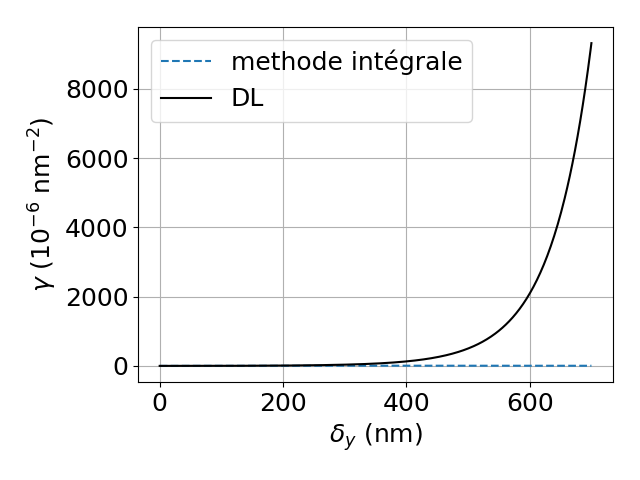

In [54]:
if plot :
        
    fig = plt.figure()

    #plt.plot(Delta_y*1e9, np.array(Res_ana*1e-12))
    plt.plot(Delta_y*1e9, Res_int*1e-12, linestyle='--', label="methode intégrale")
    plt.plot(Delta_y*1e9, -Res_DL*1e-12, color='black', label='DL')

    plt.xlabel('$\delta_y$ (nm)')
    plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')
    plt.legend()
    plt.grid()
    plt.tight_layout()

    # plt.savefig('Comparaison analytique et integral en fct de delta_y.png')
    # plt.savefig('Comparaison analytique et integral en fct de delta_y.pdf')

    # plt.savefig('Comparaison analytique et DL en fct de delta_y.png')
    # plt.savefig('Comparaison analytique et DL en fct de delta_y.pdf')

## Comparer Airy et Gaussien

On varie Delta_y

<>:11: SyntaxWarning: invalid escape sequence '\d'
<>:12: SyntaxWarning: invalid escape sequence '\g'
<>:11: SyntaxWarning: invalid escape sequence '\d'
<>:12: SyntaxWarning: invalid escape sequence '\g'
C:\Users\nberr\AppData\Local\Temp\ipykernel_15848\310726113.py:11: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel('$\delta_y$ (nm)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_15848\310726113.py:12: SyntaxWarning: invalid escape sequence '\g'
  plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')


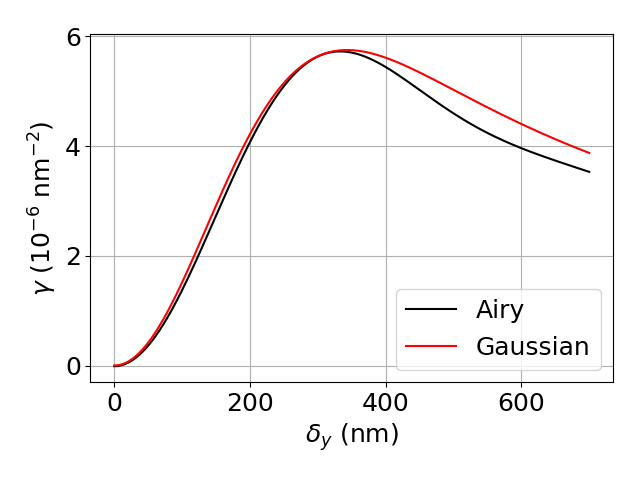

In [55]:
Res_Airy = Response_function(d0, Delta_y, beam='Airy')
Res_Gaussian = Response_function(d0, Delta_y, beam='Gaussian')


fig = plt.figure()

plt.plot(Delta_y*1e9, Res_Airy*1e-12, color='black', label='Airy')
plt.plot(Delta_y*1e9, Res_Gaussian*1e-12, color='red', label="Gaussian")
#plt.plot(Delta_y*1e9, -Res_DL*1e18, color='black', label='DL')

plt.xlabel('$\delta_y$ (nm)')
plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')
plt.legend()
plt.grid()
plt.tight_layout()
# plt.savefig('Comparaison Airy et Gaussien en fct de delta_y.png')
# plt.savefig('Comparaison Airy et Gaussien en fct de delta_y.pdf')


ON test l'influence du nombre de points d'intégration

On varie FWHM

<>:11: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\g'
<>:11: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\g'
C:\Users\nberr\AppData\Local\Temp\ipykernel_12188\2608740699.py:11: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$ (nm)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_12188\2608740699.py:12: SyntaxWarning: invalid escape sequence '\g'
  plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')


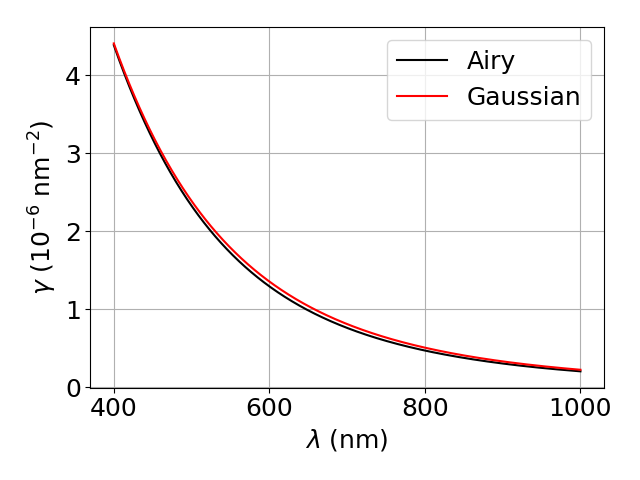

In [9]:

Res_Airy = Response_function(D0, delta_y, beam='Airy')
Res_Gaussian = Response_function(D0, delta_y, beam='Gaussian')


fig = plt.figure()

plt.plot(Lambda*1e9, Res_Airy*1e-12, color='black', label='Airy')
plt.plot(Lambda*1e9, Res_Gaussian*1e-12, color='red', label="Gaussian")
#plt.plot(Delta_y*1e9, -Res_DL*1e18, color='black', label='DL')

plt.xlabel('$\lambda$ (nm)')
plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')
plt.legend()
plt.grid()
plt.tight_layout()

# plt.savefig('Comparaison Airy et Gaussien en fct de Lambda.png')
# plt.savefig('Comparaison Airy et Gaussien en fct de Lambda.pdf')

<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:11: SyntaxWarning: invalid escape sequence '\g'
<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:11: SyntaxWarning: invalid escape sequence '\g'
C:\Users\nberr\AppData\Local\Temp\ipykernel_12188\3378187763.py:8: SyntaxWarning: invalid escape sequence '\d'
  plt.plot(D0*1e9, Res_Airy_1*1e-12, color='black', label='$\delta_y$ = 300 nm')
C:\Users\nberr\AppData\Local\Temp\ipykernel_12188\3378187763.py:11: SyntaxWarning: invalid escape sequence '\g'
  plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')


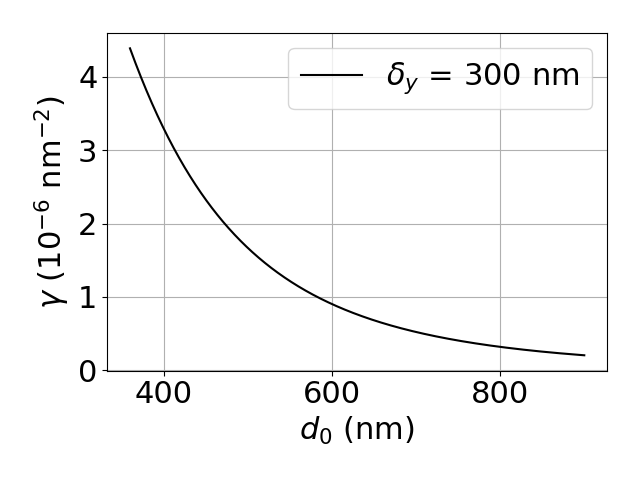

In [21]:
Res_Airy_1 = Response_function(D0, delta_y, beam='Airy')
Res_Airy_2 = Response_function(D0, 500e-9, beam='Airy')
Res_Airy_3 = Response_function(D0, 600e-9, beam='Airy')


fig = plt.figure()

plt.plot(D0*1e9, Res_Airy_1*1e-12, color='black', label='$\delta_y$ = 300 nm')

plt.xlabel('$d_0$ (nm)')
plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')
plt.legend()
plt.grid()
plt.tight_layout()

os.chdir(r'C:\Users\nberr\ENS_Lyon\M2\Stage\Rapport de stage\Figures\Diapo')

#plt.savefig('response_func.pdf',bbox_inches='tight')


<>:11: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\g'
<>:11: SyntaxWarning: invalid escape sequence '\l'
<>:12: SyntaxWarning: invalid escape sequence '\g'
C:\Users\nberr\AppData\Local\Temp\ipykernel_12188\3435293170.py:11: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$ (nm)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_12188\3435293170.py:12: SyntaxWarning: invalid escape sequence '\g'
  plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')


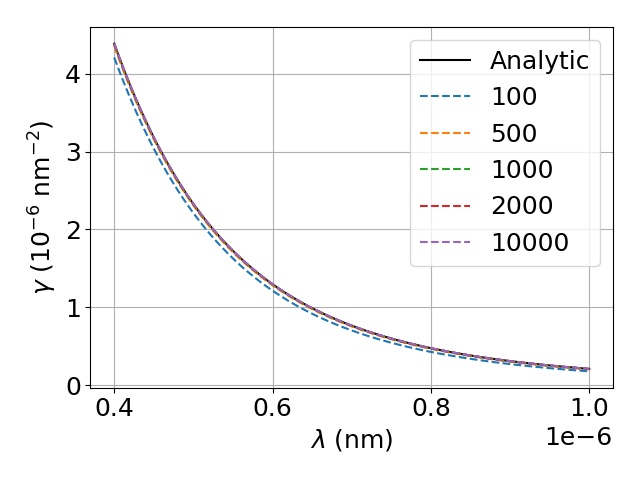

In [10]:
N = [100, 500, 1000, 2000, 10000]

fig = plt.figure()
plt.plot(Lambda, Res_ana_lda*1e-12, color='black',label='Analytic')
for n in N :
    res = Response_function(D0, delta_y,  n_points = n)

    plt.plot(Lambda, res*1e-12,linestyle='--', label = str(n))


plt.xlabel('$\lambda$ (nm)')
plt.ylabel('$\gamma$ ($10^{-6}$ nm$^{-2}$)')
plt.legend()
plt.grid()
plt.tight_layout()



<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:14: SyntaxWarning: invalid escape sequence '\D'
<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:14: SyntaxWarning: invalid escape sequence '\D'
C:\Users\nberr\AppData\Local\Temp\ipykernel_12188\2295689127.py:13: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$ (nm)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_12188\2295689127.py:14: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel('$\Delta \gamma / \gamma_{ana}$ ')


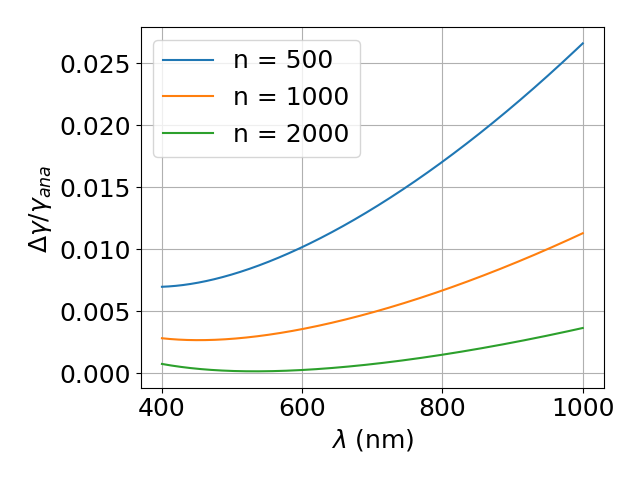

In [11]:
N = [ 500, 1000, 2000]

fig = plt.figure()



for n in N :
    res = Response_function(D0, delta_y,  n_points = n)

    plt.plot(Lambda*1e9, -(res-Res_ana_lda)/Res_ana_lda, label = 'n = {}'.format(n))


plt.xlabel('$\lambda$ (nm)')
plt.ylabel('$\Delta \gamma / \gamma_{ana}$ ')
plt.legend()
plt.grid()
plt.tight_layout()

os.chdir(r'C:\Users\nberr\ENS_Lyon\M2\Stage\Rapport de stage\Figures\Nanoscope_2')
#plt.savefig('Convergence fonction analytique.pdf')
#plt.savefig('Convergence fonction analytique.png')